In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from scipy.stats import norm
from copy import deepcopy
from scipy.stats import t as t_dist
import numpy as np
from scipy.stats import ttest_ind

### With constraints

In [2]:
K = 100
N = 10
Z = norm.ppf(0.975)
std = 3

cost = np.zeros((3,10,1000))
p_value_matrix = np.zeros((K,1000))
p_value_matrix_shrunken = np.zeros((K,1000))

anchor_mean = 1
for index1,constaint_ratio in enumerate([0.1*i for i in range(1,11)]):
    for time_seq in tqdm(range(1000)):
        true_tao = np.random.normal(anchor_mean,3, K)

        postive_true_tao = true_tao[true_tao > 0]
        if len(postive_true_tao) < int(constaint_ratio * K):
            optimal_cost = np.sum(postive_true_tao)
        else:
            sorted_tao = np.sort(postive_true_tao)
            optimal_cost = np.sum(sorted_tao[-int(constaint_ratio * K):])

        

        X = np.zeros((K,N))
        for i in range(K):
            random_set = np.random.choice(range(N), 5, replace=False)
            for j in random_set:
                X[i,j] = 1
        Y = np.zeros((K,N))
        for i in range(K):
            for j in range(N):
                Y[i,j] = true_tao[i] * X[i,j] + np.random.normal(0,std)

        #DM
        tao_hat = np.zeros(K)
        variance = np.zeros(K)
        #variance1 = np.zeros(K)
        p_value_list = np.zeros(K)
        lower_bound_DM = np.zeros(K)
        for k in range(K):
            group_1 = Y[k,X[k,:]==1]
            group_0 = Y[k,X[k,:]==0]
            t_stat, p_value = ttest_ind(group_1, group_0, equal_var = False)  
            diff_mean = group_1.mean() - group_0.mean()
            tao_hat[k] = diff_mean
            p_value_list[k] = p_value
            variance[k] = N*(group_1.var(ddof=1) / len(group_1) + group_0.var(ddof=1) / len(group_0))
            lower_bound_DM[k] = tao_hat[k] - Z * np.sqrt(variance[k]) / np.sqrt(N)
        p_value_matrix[:,time_seq] = p_value_list
            #tao_hat[i] = np.sum(Y[i,:]*X[i,:])/np.sum(X[i,:]) - np.sum(Y[i,:]*(1-X[i,:]))/np.sum(1-X[i,:])
            #variance[i] = np.sum((Y[i,:]-tao_hat[i]*X[i,:])**2)/(N)

        tao_0 = np.mean(tao_hat)
        numerator = np.mean(variance)
        denumerator = np.mean((tao_hat - tao_0)**2) - numerator/N

        bayesian_tao = np.zeros(K)
        bayesian_beta = np.zeros(K)
        posteri_mean_array = np.zeros(K)
        #p_value_list_bayesian = np.zeros(K)
        decision3 = []
        # #bayesian_variance = np.zeros(K)
        lower_bound_bayesian = np.zeros(K)
        for k in range(K):
            if denumerator <= 0:
                theta = 1
                posteri_mean = tao_hat[k]*theta + (1 - theta)*tao_0
                posteri_mean_array[k] = posteri_mean
                posteri_var = 1/(N/variance[k])
                lower_bound_bayesian[k] = posteri_mean - Z * np.sqrt(posteri_var)
                dist = norm(loc=posteri_mean, scale=np.sqrt(posteri_var))
                prob = dist.sf(0)  # survival function: P(X > x)
                if prob > 1 - 0.025:
                    decision3.append(k)
            else:
                bayesian_beta[k] = max(variance[k]/denumerator,0)
                theta = N/(N+bayesian_beta[k])
                posteri_mean = tao_hat[k]*theta + (1 - theta)*tao_0
                posteri_mean_array[k] = posteri_mean
                posteri_var = 1/(1/denumerator+ N/variance[k])
                lower_bound_bayesian[k] = posteri_mean - Z * np.sqrt(posteri_var)
                dist = norm(loc=posteri_mean, scale=np.sqrt(posteri_var))

                prob = dist.sf(0)  # survival function: P(X > x)
                if prob > 1 - 0.025:
                    decision3.append(k)
        capacity = int(constaint_ratio * K)
        if len(decision3) > int(constaint_ratio * K):
            ids = np.asarray(decision3, dtype=int)
            decision3 = ids[np.argsort(posteri_mean_array[ids])[-capacity:]]
            #decision3 = np.argsort(lower_bound_bayesian[decision3])[-int(constaint_ratio * K):]
        
        
        if anchor_mean != 0:
            beta = numerator/denumerator + Z*np.sqrt(N*numerator)/tao_0
            beta = max(0,beta)
            theta = N/(N+beta)
            #shunken_saa
            tao_shunken_hat = np.zeros(K)
            p_value_list_shrunken = np.zeros(K)
            #anchor_mean = np.mean(tao_hat)
            #theta = np.sum((true_tao - anchor_mean)**2)/(np.sum((true_tao - anchor_mean)**2)+K*50**2*2/N)
            #theta = (N/2)/((N/2) + 50**2/9)
            Y_shunken = deepcopy(Y)
            Y_shunken = theta*Y_shunken 
            lower_bound_shrunken = np.zeros(K)
            for k in range(K):
                group_1 = Y_shunken[k,X[k,:]==1] + (1-theta)*tao_0
                group_0 = Y_shunken[k,X[k,:]==0]
                t_stat, p_value = ttest_ind(group_1, group_0, equal_var = False)  
                diff_mean1 = group_1.mean() - group_0.mean()
                #variance1 = N*(group_1.var(ddof=1) / len(group_1) + group_0.var(ddof=1) / len(group_0))
                lower_bound_shrunken[k] = diff_mean1 - (Z*np.sqrt(variance[k])*theta)/np.sqrt(N)
                tao_shunken_hat[k] = diff_mean1
                p_value_list_shrunken[k] = p_value
            
            p_value_matrix_shrunken[:,time_seq] = p_value_list_shrunken
            # cost[0,index1,time_seq] = np.sum(true_tao[np.argwhere(tao_hat>(Z*np.sqrt(variance))/np.sqrt(N))])/optimal_cost
            # cost[1,index1,time_seq] = np.sum(true_tao[np.argwhere(tao_shunken_hat>(Z*np.sqrt(variance)*theta)/np.sqrt(N))])/optimal_cost
            decision1 = np.intersect1d(np.argwhere(p_value_list<0.05), np.argwhere(tao_hat>0))
            
           
            if len(decision1) > capacity:
                decision1 = decision1[np.argsort(tao_hat[decision1])[-capacity:]]
                #decision1 = np.argsort(lower_bound_DM[decision1])[-int(constaint_ratio * K):]

            decision2 = np.intersect1d(np.argwhere(p_value_list_shrunken<0.05), np.argwhere(tao_shunken_hat>0))
            if len(decision2) > capacity:
                decision2 = decision2[np.argsort(tao_shunken_hat[decision2])[-capacity:]]
                #decision2 = np.argsort(lower_bound_shrunken[decision2])[-int(constaint_ratio * K):]
            #decision3 = np.intersect1d(np.argwhere(p_value_list_bayesian<0.05), np.argwhere(bayesian_tao>0))
            cost[0,index1,time_seq] = np.sum(true_tao[decision1])/optimal_cost
            cost[1,index1,time_seq] = np.sum(true_tao[decision2])/optimal_cost
            cost[2,index1,time_seq] = np.sum(true_tao[decision3])/optimal_cost
            #cost[3,index1,time_seq] = np.sum(true_tao[decision4])/optimal_cost
            #cost[3,index1,time_seq] = np.sum(true_tao[decision4])/optimal_cost
            
            
            

100%|██████████| 1000/1000 [01:30<00:00, 11.00it/s]


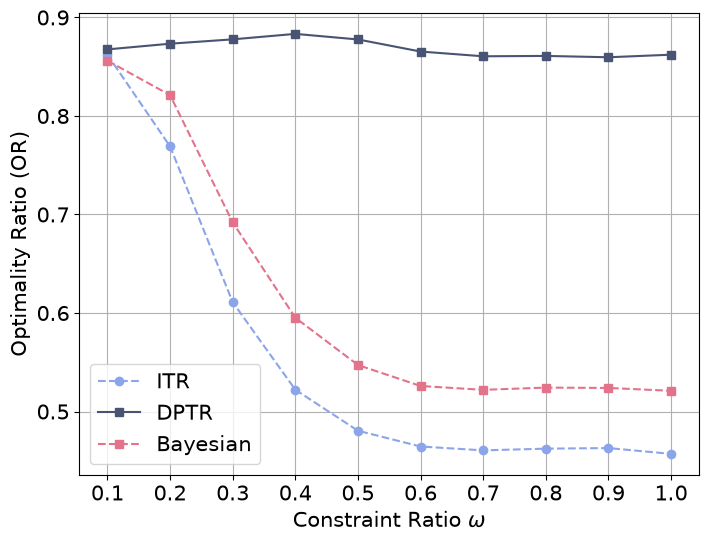

In [3]:
plt.figure(figsize=(8,6))
plt.xlabel(r'Constraint Ratio $\omega$',fontsize=15)
plt.ylabel('Optimality Ratio (OR)',fontsize=15)
x = [0.1*i for i in range(1,11)]
y3 = np.mean(cost[0],axis=1)
plt.plot(x, y3, color = '#8CA5EA',linestyle = '--', marker='o',label = "ITR")

y3 = np.mean(cost[1],axis=1)
plt.plot(x, y3, color = '#495373',marker = "s",label = "DPTR")

y3 = np.mean(cost[2],axis=1)
plt.plot(x, y3, color = '#E3738B',marker = "s",label = "Bayesian",linestyle = '--')#

plt.xticks(x,fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=15)
plt.grid()
plt.savefig('scenario1_figures/performance_compare_with_constraint.png',dpi=300,bbox_inches = 'tight')
plt.show()